# StreamVault: Data Profiling
Raw TMDb JSON -> analyst-ready DataFrames, with profiling of every table.

Run the notebook from the `Data_profiling` folder (it imports shared settings from `Data_transform`).

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Shared settings and helpers live in Data_transform
sys.path.insert(0, str(Path.cwd().parent / "Data_transform"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as cfg
from utils import read_json

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

PROFILE_DIR = cfg.PROCESSED_DIR / "profile"
PROFILE_DIR.mkdir(parents=True, exist_ok=True)
print("Details file exists:", cfg.DETAILS_FILE.exists())
print("Credits file exists:", cfg.CREDITS_FILE.exists())

Details file exists: True
Credits file exists: True


## 2. Load the raw JSON

In [2]:
details = read_json(cfg.DETAILS_FILE)
credits = read_json(cfg.CREDITS_FILE)
print(f"Details records: {len(details)} | Credits records: {len(credits)}")

Details records: 112 | Credits records: 112


## 3. Nested JSON -> flat DataFrames
One table per grain: films, film-genres, film-cast, film-crew.

In [3]:
# Movies: one row per film; single nested objects become columns
movies_df = pd.json_normalize(details, sep="_")
movies_df["release_date"] = pd.to_datetime(movies_df["release_date"], errors="coerce")
movies_df["release_year"] = movies_df["release_date"].dt.year.astype("Int64")
valid_budget = movies_df["budget"] > 0
movies_df["roi"] = movies_df["revenue"].where(valid_budget) / movies_df["budget"].where(valid_budget)
movies_df["is_franchise_member"] = movies_df["belongs_to_collection_id"].notna()

# Genres: list of objects -> one row per (film, genre)
genres_df = pd.json_normalize(details, record_path="genres", meta=["id"], meta_prefix="movie_")
genres_df = genres_df.rename(columns={"id": "genre_id", "name": "genre_name", "movie_id": "id"})

# Cast and crew: one row per (film, person)
cast_df = pd.json_normalize(credits, record_path="cast", meta=["id"], meta_prefix="movie_")
crew_df = pd.json_normalize(credits, record_path="crew", meta=["id"], meta_prefix="movie_")
cast_df = cast_df.rename(columns={"id": "person_id", "movie_id": "id"})
crew_df = crew_df.rename(columns={"id": "person_id", "movie_id": "id"})

# Drop bulky columns analysts never use
drop_cols = [c for c in movies_df.columns if c.endswith("_path")] + [
    "overview", "tagline", "homepage", "production_companies",
    "production_countries", "spoken_languages", "genres",
    "origin_country", "belongs_to_collection"]
movies_df = movies_df.drop(columns=drop_cols, errors="ignore")
cast_df = cast_df.drop(columns=["profile_path"], errors="ignore")
crew_df = crew_df.drop(columns=["profile_path"], errors="ignore")

for name, df in {"movies_df": movies_df, "genres_df": genres_df,
                 "cast_df": cast_df, "crew_df": crew_df}.items():
    print(f"{name:10s} {df.shape}")

movies_df  (112, 21)
genres_df  (320, 3)
cast_df    (7827, 12)
crew_df    (24931, 11)


In [4]:
movies_df.head()

,adult,budget,id,imdb_id,original_language,original_title,popularity,release_date,revenue,runtime,softcore,status,title,video,vote_average,vote_count,belongs_to_collection_id,belongs_to_collection_name,release_year,roi,is_franchise_member
0,False,185000000,155,tt0468569,en,The Dark Knight,59.9238,2008-07-16,1008480529,152,False,Released,The Dark Knight,False,8.540,37415,263.0,The Dark Knight Collection,2008,5.451246,True
1,False,40000000,165,tt0096874,en,Back to the Future Part II,10.6246,1989-11-22,332861197,108,False,Released,Back to the Future Part II,False,7.784,14535,264.0,Back to the Future Collection,1989,8.321530,True
2,False,54000000,242,tt0099674,en,The Godfather Part III,14.0385,1990-12-25,136766062,162,False,Released,The Godfather Part III,False,7.400,7202,230.0,The Godfather Collection,1990,2.532705,True
3,False,250000000,49026,tt1345836,en,The Dark Knight Rises,20.7093,2012-07-17,1081041287,165,False,Released,The Dark Knight Rises,False,7.801,25338,263.0,The Dark Knight Collection,2012,4.324165,True
4,False,50000000,8077,tt0103644,en,Alien³,8.3871,1992-05-22,159773545,114,False,Released,Alien³,False,6.391,6726,8091.0,Alien Collection,1992,3.195471,True


In [5]:
cast_df.head()

,adult,gender,person_id,known_for_department,name,original_name,popularity,cast_id,character,credit_id,order,id
0,False,2,3894,Acting,Christian Bale,Christian Bale,4.4776,35,Bruce Wayne,52fe4220c3a36847f8005d17,0,155
1,False,2,1810,Acting,Heath Ledger,Heath Ledger,3.3163,3,Joker,52fe421fc3a36847f8005cbf,1,155
2,False,2,6383,Acting,Aaron Eckhart,Aaron Eckhart,3.5254,15,Harvey Dent,52fe4220c3a36847f8005cf1,2,155
3,False,2,3895,Acting,Michael Caine,Michael Caine,5.2365,17,Alfred,52fe4220c3a36847f8005cf9,3,155
4,False,1,1579,Acting,Maggie Gyllenhaal,Maggie Gyllenhaal,3.0503,8,Rachel,52fe421fc3a36847f8005cd5,4,155


In [ ]:
crew_df.head()

## 4. Column profile
Type, missing values and unique counts for every column in every table.

In [6]:
def profile_columns(df, table):
    return pd.DataFrame({
        "table": table,
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "missing": df.isna().sum().values,
        "missing_pct": (df.isna().mean() * 100).round(1).values,
        "unique": df.nunique(dropna=True).values,
    })

col_profile = pd.concat([
    profile_columns(movies_df, "movies"),
    profile_columns(genres_df, "genres"),
    profile_columns(cast_df, "cast"),
    profile_columns(crew_df, "crew"),
], ignore_index=True)
col_profile.to_csv(PROFILE_DIR / "profile_columns.csv", index=False)

# Columns with missing values
col_profile[col_profile["missing"] > 0]

,table,column,dtype,missing,missing_pct,unique
16,movies,belongs_to_collection_id,float64,16,14.3,32
17,movies,belongs_to_collection_name,str,16,14.3,32
39,crew,known_for_department,str,1,0.0,13


## 5. Numeric profile and outliers
Outliers use the 1.5 x IQR rule.

In [7]:
num_cols = ["budget", "revenue", "roi", "runtime", "vote_average",
            "vote_count", "popularity", "release_year"]
num = movies_df[num_cols].astype(float)
desc = num.describe().T
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
desc["zeros"] = (num == 0).sum()
desc["outliers_iqr"] = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
desc = desc.round(2)
desc.to_csv(PROFILE_DIR / "profile_numeric.csv")
desc

,count,mean,std,min,25%,50%,75%,max,zeros,outliers_iqr
budget,112.0,1.084460e+08,8.278818e+07,1200000.00,3.808750e+07,9.100000e+07,1.500000e+08,3.790000e+08,0,2
revenue,112.0,5.996588e+08,4.362467e+08,7390108.00,2.953463e+08,5.195630e+08,8.726984e+08,2.942650e+09,0,2
roi,112.0,8.500000e+00,1.038000e+01,1.13,3.800000e+00,5.370000e+00,8.850000e+00,7.049000e+01,0,11
runtime,112.0,1.304900e+02,2.554000e+01,81.00,1.150000e+02,1.285000e+02,1.432500e+02,2.020000e+02,0,3
vote_average,112.0,7.590000e+00,7.100000e-01,5.75,7.200000e+00,7.720000e+00,8.160000e+00,8.730000e+00,0,1
vote_count,112.0,1.754420e+04,8.271550e+03,4137.00,1.104225e+04,1.584700e+04,2.282725e+04,4.193500e+04,0,2
popularity,112.0,2.017000e+01,1.339000e+01,0.48,1.067000e+01,1.696000e+01,2.474000e+01,8.890000e+01,0,6
release_year,112.0,2.000180e+03,1.114000e+01,1966.00,1.993750e+03,2.002500e+03,2.008000e+03,2.019000e+03,0,2


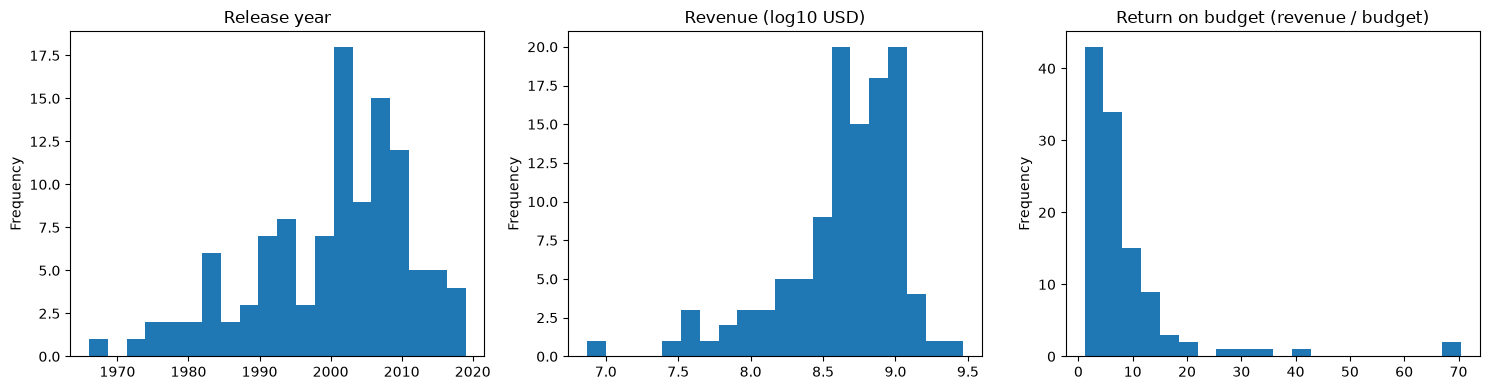

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
movies_df["release_year"].astype(float).plot.hist(bins=20, ax=axes[0], title="Release year")
np.log10(movies_df["revenue"]).plot.hist(bins=20, ax=axes[1], title="Revenue (log10 USD)")
movies_df["roi"].plot.hist(bins=20, ax=axes[2], title="Return on budget (revenue / budget)")
plt.tight_layout()
plt.show()

## 6. Data-quality checks

In [9]:
ledger = pd.read_csv(cfg.LEDGER_FILE) if cfg.LEDGER_FILE.exists() else None
dirs_per_film = crew_df[crew_df["job"] == "Director"].groupby("id").size()
cast_per_film = cast_df.groupby("id").size()

checks = [
    ("film ids unique in details", movies_df["id"].is_unique),
    ("film ids unique in credits", pd.Series([c["id"] for c in credits]).is_unique),
    ("details and credits cover the same films", set(movies_df["id"]) == {c["id"] for c in credits}),
    ("no zero/missing budget", int((movies_df["budget"].fillna(0) == 0).sum()) == 0),
    ("no zero/missing revenue", int((movies_df["revenue"].fillna(0) == 0).sum()) == 0),
    ("no revenue below budget", int((movies_df["revenue"] < movies_df["budget"]).sum()) == 0),
    ("all films have a release date", movies_df["release_date"].notna().all()),
    ("all films status = Released", (movies_df["status"] == "Released").all()),
    ("every film has a director", len(dirs_per_film) == len(movies_df)),
    ("every film has >= 3 cast members", bool((cast_per_film >= 3).all())),
    ("no duplicate (film, person) cast rows", not cast_df.duplicated(["id", "person_id", "character"]).any()),
    ("no duplicate imdb ids", not movies_df["imdb_id"].dropna().duplicated().any()),
]
if ledger is not None:
    checks.append(("every input row accounted for in ledger", ledger["status"].notna().all()))

check_df = pd.DataFrame(checks, columns=["check", "passed"])
check_df["passed"] = check_df["passed"].astype(bool)
check_df.to_csv(PROFILE_DIR / "profile_checks.csv", index=False)
check_df

,check,passed
0,film ids unique in details,True
1,film ids unique in credits,True
2,details and credits cover the same films,True
3,no zero/missing budget,True
4,no zero/missing revenue,True
5,no revenue below budget,True
6,all films have a release date,True
7,all films status = Released,True
8,every film has a director,True
9,every film has >= 3 cast members,True


## 7. Findings that need analyst attention

In [10]:
coll_size = movies_df.groupby("belongs_to_collection_id")["id"].transform("size")

print("Films released before", cfg.CUTOFF_YEAR, ":", int((movies_df["release_year"] < cfg.CUTOFF_YEAR).sum()))
print("Franchise members:", int(movies_df["is_franchise_member"].sum()),
      "| standalone:", int((~movies_df["is_franchise_member"]).sum()))
print("Films in a collection with only 1 film in the list:", int((coll_size == 1).sum()))
print("Films with more than one director credit:", int((dirs_per_film > 1).sum()))
print("Non-English originals:", int((movies_df["original_language"] != "en").sum()))

Films released before 2000 : 41
Franchise members: 96 | standalone: 16
Films in a collection with only 1 film in the list: 9
Films with more than one director credit: 9
Non-English originals: 2


In [11]:
# Where the input rows went
ledger["status"].value_counts().rename("rows").to_frame() if ledger is not None else "No ledger found - run extract.py first"

,rows
status,
fetched,112
dropped_duplicate,7
dropped_not_found_in_api,5
dropped_missing_id,2
dropped_invalid_id,1


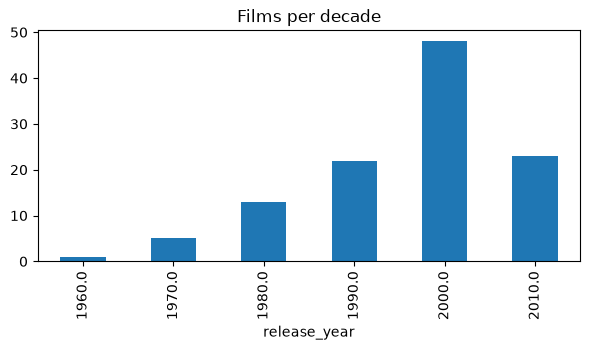

belongs_to_collection_name
Harry Potter Collection                8
Star Wars Collection                   6
Pirates of the Caribbean Collection    5
Mission: Impossible Collection         5
Die Hard Collection                    4
Shrek Collection                       4
Indiana Jones Collection               4
Alien Collection                       4
The Avengers Collection                4
Toy Story Collection                   4
Name: id, dtype: int64

In [12]:
decades = (movies_df["release_year"].astype(float) // 10 * 10).value_counts().sort_index()
decades.plot.bar(title="Films per decade", figsize=(7, 3))
plt.show()

# Largest collections in the list
movies_df.groupby("belongs_to_collection_name")["id"].size().sort_values(ascending=False).head(10)

## 8. Save analyst-ready tables

In [ ]:
movies_df.to_csv(PROFILE_DIR / "movies_df.csv", index=False)
genres_df.to_csv(PROFILE_DIR / "genres_df.csv", index=False)
cast_df.to_csv(PROFILE_DIR / "cast_df.csv", index=False)
crew_df.to_csv(PROFILE_DIR / "crew_df.csv", index=False)
print("Saved to", PROFILE_DIR)